# GraphSAGE Explainability with GNNExplainer

This notebook runs the trained GraphSAGE model on the test graphs and creates UI-ready explanations for all three tasks:

1. Binary attack detection
2. MITRE tactic prediction
3. MITRE technique prediction

The notebook evaluates all test edges, but detailed GNNExplainer explanations are generated for a configurable number of selected test edges because explaining every edge is computationally expensive.

## 1. Imports and configuration

In [34]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch_geometric.explain import Explainer, GNNExplainer

GRAPH_DIR = Path(".")
CHECKPOINT_PATH = GRAPH_DIR / "graphsage_exp1_best_model.pt"
TEST_GRAPHS_PATH = GRAPH_DIR / "test_graphs.pt"
PREPROCESSING_PATH = GRAPH_DIR / "preprocessing_objects.joblib"
TEST_METADATA_PATH = GRAPH_DIR / "test_edges.parquet"
OUTPUT_PATH = GRAPH_DIR / "gnn_explanations_ui.json"

BINARY_THRESHOLD = 0.5
NUMBER_OF_EDGES_TO_EXPLAIN = 20
TOP_K_FEATURES = 5
TOP_K_NEIGHBOR_EDGES = 5
GNNEXPLAINER_EPOCHS = 100

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cuda


## 2. Load graphs, metadata, preprocessing objects, and checkpoint

In [35]:
def load_torch_file(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location="cpu")


test_graphs = load_torch_file(TEST_GRAPHS_PATH)
preprocessing_objects = joblib.load(PREPROCESSING_PATH)
checkpoint = load_torch_file(CHECKPOINT_PATH)

tactic_encoder = preprocessing_objects["tactic_encoder"]
mitre_encoder = preprocessing_objects["mitre_encoder"]
edge_category_encoder = preprocessing_objects[
    "edge_category_encoder"
]

test_metadata = pd.read_parquet(
    TEST_METADATA_PATH
).reset_index(drop=True)

print("Test graphs:", len(test_graphs))
print("Test metadata rows:", len(test_metadata))

Test graphs: 2518
Test metadata rows: 69161


## 3. Define the same GraphSAGE architecture used during training

In [36]:
class GraphSAGEEdgeClassifier(nn.Module):
    def __init__(
        self,
        node_input_dim,
        edge_input_dim,
        hidden_dim,
        tactic_dim,
        mitre_dim,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = SAGEConv(node_input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.dropout = dropout

        edge_input_size = hidden_dim * 2 + edge_input_dim

        self.binary_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.tactic_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, tactic_dim)
        )

        self.mitre_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, mitre_dim)
        )

    def forward(self, data):
        x = self.conv1(data.x, data.edge_index)
        x = F.relu(x)
        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(x, data.edge_index)
        x = F.relu(x)

        source_nodes = data.edge_index[0]
        destination_nodes = data.edge_index[1]

        edge_representation = torch.cat(
            [
                x[source_nodes],
                x[destination_nodes],
                data.edge_attr
            ],
            dim=1
        )

        binary_logits = self.binary_head(
            edge_representation
        ).squeeze(1)

        tactic_logits = self.tactic_head(edge_representation)
        mitre_logits = self.mitre_head(edge_representation)

        return binary_logits, tactic_logits, mitre_logits


model = GraphSAGEEdgeClassifier(
    **checkpoint["model_config"]
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded.")

Checkpoint loaded.


## 4. Define feature names for the UI

In [37]:
numeric_edge_feature_names = [
    "connection_count",
    "total_duration",
    "average_duration",
    "maximum_duration",
    "total_orig_bytes",
    "total_resp_bytes",
    "total_orig_packets",
    "total_resp_packets",
    "total_orig_ip_bytes",
    "total_resp_ip_bytes",
    "total_missed_bytes",
    "unique_destination_ports",
    "most_common_destination_port",
    "tcp_count",
    "udp_count",
    "icmp_count"
]

categorical_edge_feature_names = (
    edge_category_encoder
    .get_feature_names_out([
        "most_common_service",
        "most_common_connection_state"
    ])
    .tolist()
)

edge_feature_names = (
    numeric_edge_feature_names
    + categorical_edge_feature_names
)

node_feature_names = [
    "outgoing_edge_count",
    "outgoing_connection_count",
    "unique_destinations",
    "outgoing_duration",
    "outgoing_orig_bytes",
    "outgoing_orig_packets",
    "outgoing_orig_ip_bytes",
    "outgoing_missed_bytes",
    "outgoing_tcp_count",
    "outgoing_udp_count",
    "outgoing_icmp_count",
    "incoming_edge_count",
    "incoming_connection_count",
    "unique_sources",
    "incoming_duration",
    "incoming_resp_bytes",
    "incoming_resp_packets",
    "incoming_resp_ip_bytes",
    "incoming_missed_bytes",
    "incoming_tcp_count",
    "incoming_udp_count",
    "incoming_icmp_count"
]

print("Edge feature names:", len(edge_feature_names))
print("Node feature names:", len(node_feature_names))

Edge feature names: 56
Node feature names: 22


## 5. Run predictions for every test edge

The metadata must be the exact test edge dataframe used to create the graph objects and must have the same row order.

In [38]:
total_graph_edges = sum(
    graph.num_edges for graph in test_graphs
)

if total_graph_edges != len(test_metadata):
    raise ValueError(
        "Graph and metadata edge counts do not match."
    )


all_predictions = []
edge_locations = []
metadata_position = 0

with torch.no_grad():
    for graph_index, graph in enumerate(test_graphs):
        graph_device = graph.to(DEVICE)
        binary_logits, tactic_logits, mitre_logits = model(
            graph_device
        )

        binary_probabilities = torch.sigmoid(
            binary_logits
        ).cpu().numpy()

        tactic_probabilities = torch.sigmoid(
            tactic_logits
        ).cpu().numpy()

        mitre_probabilities = torch.sigmoid(
            mitre_logits
        ).cpu().numpy()

        for local_edge_index in range(graph.num_edges):
            metadata_row = test_metadata.iloc[
                metadata_position + local_edge_index
            ]

            attack_probability = float(
                binary_probabilities[local_edge_index]
            )

            tactic_index = int(
                np.argmax(
                    tactic_probabilities[local_edge_index]
                )
            )

            mitre_index = int(
                np.argmax(
                    mitre_probabilities[local_edge_index]
                )
            )

            all_predictions.append({
                "metadata_index": metadata_position + local_edge_index,
                "graph_index": graph_index,
                "local_edge_index": local_edge_index,
                "window_start": metadata_row["window_start"],
                "src_ip_zeek": str(
                    metadata_row["src_ip_zeek"]
                ),
                "dest_ip_zeek": str(
                    metadata_row["dest_ip_zeek"]
                ),
                "binary_probability": attack_probability,
                "binary_label": (
                    "attack"
                    if attack_probability >= BINARY_THRESHOLD
                    else "benign"
                ),
                "tactic_index": tactic_index,
                "tactic_label": str(
                    tactic_encoder.classes_[tactic_index]
                ),
                "tactic_confidence": float(
                    tactic_probabilities[
                        local_edge_index,
                        tactic_index
                    ]
                ),
                "mitre_index": mitre_index,
                "mitre_label": str(
                    mitre_encoder.classes_[mitre_index]
                ),
                "mitre_confidence": float(
                    mitre_probabilities[
                        local_edge_index,
                        mitre_index
                    ]
                )
            })

            edge_locations.append((
                graph_index,
                local_edge_index
            ))

        metadata_position += graph.num_edges

print("Predictions generated:", len(all_predictions))

Predictions generated: 69161


## 6. Select test edges for detailed explanations

GNNExplainer is computationally expensive. The model is evaluated on every test edge, but detailed explanations are generated for a selected subset. This selection chooses attack predictions first, followed by other test edges if needed.

In [39]:
attack_candidates = [
    prediction
    for prediction in all_predictions
    if prediction["binary_label"] == "attack"
]

attack_candidates = sorted(
    attack_candidates,
    key=lambda item: item["binary_probability"],
    reverse=True
)

selected_predictions = attack_candidates[
    :NUMBER_OF_EDGES_TO_EXPLAIN
]

print(
    "Edges selected for explanation:",
    len(selected_predictions)
)

Edges selected for explanation: 20


## 7. Create task-specific GNNExplainer wrappers

The original model returns three outputs. The wrappers expose one head at a time so GNNExplainer can explain a specific binary label, tactic class, or MITRE technique class.

In [40]:
class HeadWrapper(nn.Module):
    def __init__(self, base_model, task_name):
        super().__init__()
        self.base_model = base_model
        self.task_name = task_name

    def forward(self, x, edge_index, edge_attr):
        data = Data(
            x=x,
            edge_index=edge_index,
            edge_attr=edge_attr
        )

        binary_logits, tactic_logits, mitre_logits = (
            self.base_model(data)
        )

        if self.task_name == "binary":
            return binary_logits.unsqueeze(1)

        if self.task_name == "tactic":
            return tactic_logits

        if self.task_name == "mitre":
            return mitre_logits

        raise ValueError(
            f"Unknown task: {self.task_name}"
        )


def create_explainer(task_name):
    task_mode = (
        "binary_classification"
        if task_name == "binary"
        else "multiclass_classification"
    )

    return Explainer(
        model=HeadWrapper(model, task_name),
        algorithm=GNNExplainer(
            epochs=GNNEXPLAINER_EPOCHS
        ),
        explanation_type="model",
        node_mask_type="attributes",
        edge_mask_type="object",
        model_config={
            "mode": task_mode,
            "task_level": "edge",
            "return_type": "raw"
        }
    )

## 8. Convert explanation masks into UI-friendly information

In [41]:
def top_feature_importances(mask, feature_names, top_k):
    if mask is None:
        return []

    mask = mask.detach().cpu()

    if mask.ndim == 2:
        importance = mask.abs().mean(dim=0).numpy()
    else:
        importance = mask.abs().numpy()

    order = np.argsort(importance)[::-1][:top_k]

    return [
        {
            "feature": str(feature_names[index]),
            "importance": float(importance[index])
        }
        for index in order
    ]


def top_neighbor_edges(
    graph,
    edge_mask,
    graph_metadata,
    top_k
):
    if edge_mask is None:
        return []

    edge_importance = edge_mask.detach().cpu().numpy()
    order = np.argsort(edge_importance)[::-1]
    results = []

    for local_edge_index in order:
        if len(results) >= top_k:
            break

        row = graph_metadata.iloc[local_edge_index]
        results.append({
            "source_ip": str(row["src_ip_zeek"]),
            "destination_ip": str(
                row["dest_ip_zeek"]
            ),
            "importance": float(
                edge_importance[local_edge_index]
            )
        })

    return results


def explain_one_task(
    task_name,
    graph,
    edge_index,
    target_index,
    graph_metadata
):
    neighbor_explainer = create_explainer(task_name)
    graph_device = graph.to(DEVICE)

    target = torch.tensor(
        [target_index],
        dtype=torch.long,
        device=DEVICE
    )

    neighbor_explanation = neighbor_explainer(
        x=graph_device.x,
        edge_index=graph_device.edge_index,
        edge_attr=graph_device.edge_attr,
        index=edge_index,
        target=target
    )

    edge_attr = graph_device.edge_attr.detach().clone()
    edge_attr.requires_grad_(True)

    gradient_graph = Data(
        x=graph_device.x,
        edge_index=graph_device.edge_index,
        edge_attr=edge_attr
    )

    gradient_outputs = HeadWrapper(
        model,
        task_name
    )(
        gradient_graph.x,
        gradient_graph.edge_index,
        gradient_graph.edge_attr
    )

    if task_name == "binary":
        selected_score = gradient_outputs[
            edge_index,
            0
        ]
    else:
        selected_score = gradient_outputs[
            edge_index,
            target_index
        ]

    model.zero_grad(set_to_none=True)
    if edge_attr.grad is not None:
        edge_attr.grad.zero_()
    selected_score.backward()

    edge_feature_importance = edge_attr.grad[
        edge_index
    ].abs().detach().cpu().numpy()

    edge_feature_order = np.argsort(
        edge_feature_importance
    )[::-1][:TOP_K_FEATURES]

    important_edge_features = [
        {
            "feature": str(edge_feature_names[index]),
            "importance": float(
                edge_feature_importance[index]
            )
        }
        for index in edge_feature_order
    ]

    return {
        "task": task_name,
        "target_index": int(target_index),
        "important_node_features": top_feature_importances(
            neighbor_explanation.node_mask,
            node_feature_names,
            TOP_K_FEATURES
        ),
        "important_edge_features": important_edge_features,
        "important_neighbor_edges": top_neighbor_edges(
            graph,
            neighbor_explanation.edge_mask,
            graph_metadata,
            TOP_K_NEIGHBOR_EDGES
        )
    }

## 9. Generate UI-ready explanation records

In [42]:
def json_safe(value):
    if isinstance(value, dict):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, list):
        return [json_safe(item) for item in value]

    if isinstance(value, np.generic):
        return value.item()

    if pd.isna(value):
        return None

    return value


ui_records = []

for prediction in selected_predictions:
    graph_index = prediction["graph_index"]
    local_edge_index = prediction["local_edge_index"]
    graph = test_graphs[graph_index]

    graph_start = sum(
        test_graphs[index].num_edges
        for index in range(graph_index)
    )

    graph_metadata = test_metadata.iloc[
        graph_start:graph_start + graph.num_edges
    ].reset_index(drop=True)

    binary_explanation = explain_one_task(
        "binary",
        graph,
        local_edge_index,
        int(
            prediction["binary_label"] == "attack"
        ),
        graph_metadata
    )

    tactic_explanation = explain_one_task(
        "tactic",
        graph,
        local_edge_index,
        prediction["tactic_index"],
        graph_metadata
    )

    mitre_explanation = explain_one_task(
        "mitre",
        graph,
        local_edge_index,
        prediction["mitre_index"],
        graph_metadata
    )

    window_start = prediction["window_start"]
    if hasattr(window_start, "isoformat"):
        window_start = window_start.isoformat()

    ui_records.append({
        "event_id": (
            f"uwf-test-{prediction['metadata_index']}"
        ),
        "row_id": prediction["metadata_index"],
        "event": {
            "window_start": window_start,
            "source_ip": prediction["src_ip_zeek"],
            "destination_ip": prediction["dest_ip_zeek"]
        },
        "gnn_detection": {
            "binary_prediction": {
                "label": prediction["binary_label"],
                "attack_probability": prediction[
                    "binary_probability"
                ],
                "confidence_type": "sigmoid"
            },
            "tactic_prediction": {
                "label": prediction["tactic_label"],
                "confidence": prediction[
                    "tactic_confidence"
                ],
                "confidence_type": "independent_sigmoid"
            },
            "mitre_prediction": {
                "technique_id": prediction["mitre_label"],
                "confidence": prediction[
                    "mitre_confidence"
                ],
                "confidence_type": "independent_sigmoid"
            }
        },
        "explanations": {
            "binary": binary_explanation,
            "tactic": tactic_explanation,
            "mitre": mitre_explanation
        }
    })

ui_records = json_safe(ui_records)

with open(OUTPUT_PATH, "w", encoding="utf-8") as output_file:
    json.dump(ui_records, output_file, indent=2)

print("Saved records:", len(ui_records))
print("Output path:", OUTPUT_PATH)
print(json.dumps(ui_records[0], indent=2))

/tmp/ipykernel_419/1517891512.py:70: UserWarning: The 'target' should not be provided for the explanation type 'model'
  neighbor_explanation = neighbor_explainer(


Saved records: 20
Output path: gnn_explanations_ui.json
{
  "event_id": "uwf-test-66034",
  "row_id": 66034,
  "event": {
    "window_start": "2022-01-09T03:45:00",
    "source_ip": "fe80::f862:2895:ecac:131b",
    "destination_ip": "ff02::1:2"
  },
  "gnn_detection": {
    "binary_prediction": {
      "label": "attack",
      "attack_probability": 1.0,
      "confidence_type": "sigmoid"
    },
    "tactic_prediction": {
      "label": "Reconnaissance",
      "confidence": 0.9042744636535645,
      "confidence_type": "independent_sigmoid"
    },
    "mitre_prediction": {
      "technique_id": "T1595",
      "confidence": 0.9246103763580322,
      "confidence_type": "independent_sigmoid"
    }
  },
  "explanations": {
    "binary": {
      "task": "binary",
      "target_index": 1,
      "important_node_features": [
        {
          "feature": "unique_destinations",
          "importance": 0.1492435187101364
        },
        {
          "feature": "incoming_resp_bytes",
          "

## 10. Improve explanation output

This section removes zero-importance neighbors, adds ground truth when it is available, and calculates a simple faithfulness check. The faithfulness check masks the top edge features and measures how much the selected prediction logit changes.

In [43]:
def safe_label_list(value):
    if value is None:
        return []
    if isinstance(value, (list, tuple, np.ndarray)):
        return [str(item) for item in value]
    if pd.isna(value):
        return []
    return [str(value)]


def get_ground_truth(row):
    if "binary_target" in row.index:
        binary_value = int(row["binary_target"])
    elif "label_binary" in row.index:
        binary_value = {
            "True": 1,
            "False": 0,
            "1": 1,
            "0": 0
        }.get(str(row["label_binary"]))
    else:
        binary_value = None

    tactic_column = (
        "tactic_targets"
        if "tactic_targets" in row.index
        else "label_tactic"
    )
    mitre_column = (
        "mitre_targets"
        if "mitre_targets" in row.index
        else "label_technique"
    )

    if binary_value is None and (
        tactic_column not in row.index
        and mitre_column not in row.index
    ):
        return None

    return {
        "label_binary": binary_value,
        "label_tactic": safe_label_list(
            row.get(tactic_column)
        ),
        "label_technique": safe_label_list(
            row.get(mitre_column)
        )
    }


def target_logit(task_name, outputs, edge_index, target_index):
    binary_logits, tactic_logits, mitre_logits = outputs

    if task_name == "binary":
        return binary_logits[edge_index]
    if task_name == "tactic":
        return tactic_logits[edge_index, target_index]
    return mitre_logits[edge_index, target_index]


def measure_edge_feature_faithfulness(
    task_name,
    graph,
    edge_index,
    target_index,
    important_features
):
    feature_indices = [
        edge_feature_names.index(item["feature"])
        for item in important_features
        if item["feature"] in edge_feature_names
    ]

    if not feature_indices:
        return None

    graph_device = graph.to(DEVICE)

    with torch.no_grad():
        original_outputs = model(graph_device)
        original_score = target_logit(
            task_name,
            original_outputs,
            edge_index,
            target_index
        )

        masked_edge_attr = graph_device.edge_attr.clone()
        masked_edge_attr[edge_index, feature_indices] = 0.0

        masked_graph = Data(
            x=graph_device.x,
            edge_index=graph_device.edge_index,
            edge_attr=masked_edge_attr
        )

        masked_outputs = model(masked_graph)
        masked_score = target_logit(
            task_name,
            masked_outputs,
            edge_index,
            target_index
        )

    original_value = float(original_score.item())
    masked_value = float(masked_score.item())

    return {
        "original_logit": original_value,
        "masked_logit": masked_value,
        "logit_drop": original_value - masked_value,
        "interpretation": (
            "positive drop means the selected features supported "
            "the prediction"
        )
    }


for record in ui_records:
    record["explanations"]["binary"][
        "important_neighbor_edges"
    ] = [
        item
        for item in record["explanations"]["binary"][
            "important_neighbor_edges"
        ]
        if item["importance"] > 1e-8
    ]

    record["explanations"]["tactic"][
        "important_neighbor_edges"
    ] = [
        item
        for item in record["explanations"]["tactic"][
            "important_neighbor_edges"
        ]
        if item["importance"] > 1e-8
    ]

    record["explanations"]["mitre"][
        "important_neighbor_edges"
    ] = [
        item
        for item in record["explanations"]["mitre"][
            "important_neighbor_edges"
        ]
        if item["importance"] > 1e-8
    ]

    metadata_index = record["row_id"]
    metadata_row = test_metadata.iloc[metadata_index]
    record["event"]["ground_truth"] = get_ground_truth(
        metadata_row
    )

    prediction = next(
        item
        for item in all_predictions
        if item["metadata_index"] == metadata_index
    )

    graph = test_graphs[prediction["graph_index"]]

    record["explanations"]["faithfulness"] = {
        "binary": measure_edge_feature_faithfulness(
            "binary",
            graph,
            prediction["local_edge_index"],
            int(prediction["binary_label"] == "attack"),
            record["explanations"]["binary"][
                "important_edge_features"
            ]
        ),
        "tactic": measure_edge_feature_faithfulness(
            "tactic",
            graph,
            prediction["local_edge_index"],
            prediction["tactic_index"],
            record["explanations"]["tactic"][
                "important_edge_features"
            ]
        ),
        "mitre": measure_edge_feature_faithfulness(
            "mitre",
            graph,
            prediction["local_edge_index"],
            prediction["mitre_index"],
            record["explanations"]["mitre"][
                "important_edge_features"
            ]
        )
    }

with open(OUTPUT_PATH, "w", encoding="utf-8") as output_file:
    json.dump(ui_records, output_file, indent=2, default=str)

print("Updated UI explanation file:", OUTPUT_PATH)

Updated UI explanation file: gnn_explanations_ui.json


## 11. Visualize the explanation for one test edge

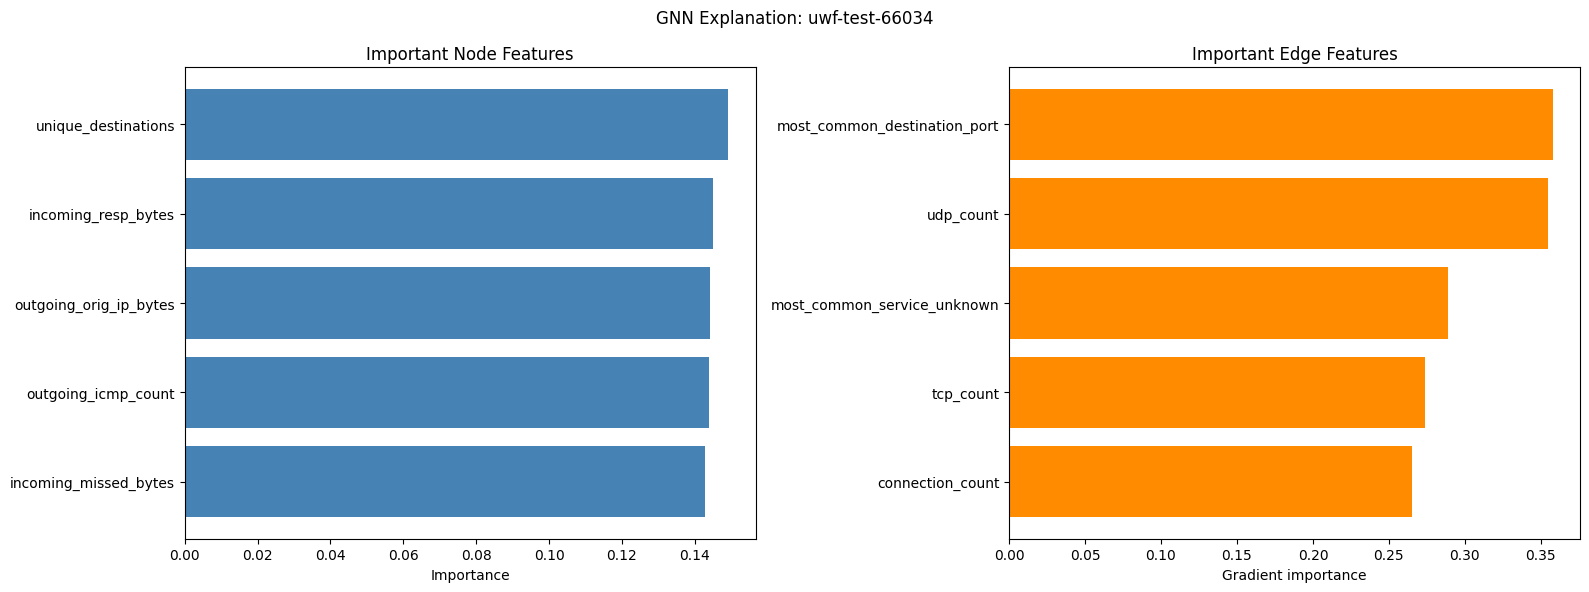

In [44]:
sample_record = ui_records[0]
binary_explanation = sample_record[
    "explanations"
]["binary"]

node_items = binary_explanation[
    "important_node_features"
]
edge_items = binary_explanation[
    "important_edge_features"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    [item["feature"] for item in node_items][::-1],
    [item["importance"] for item in node_items][::-1],
    color="steelblue"
)
axes[0].set_title("Important Node Features")
axes[0].set_xlabel("Importance")

axes[1].barh(
    [item["feature"] for item in edge_items][::-1],
    [item["importance"] for item in edge_items][::-1],
    color="darkorange"
)
axes[1].set_title("Important Edge Features")
axes[1].set_xlabel("Gradient importance")

plt.suptitle(
    f"GNN Explanation: {sample_record['event_id']}"
)
plt.tight_layout()
plt.show()

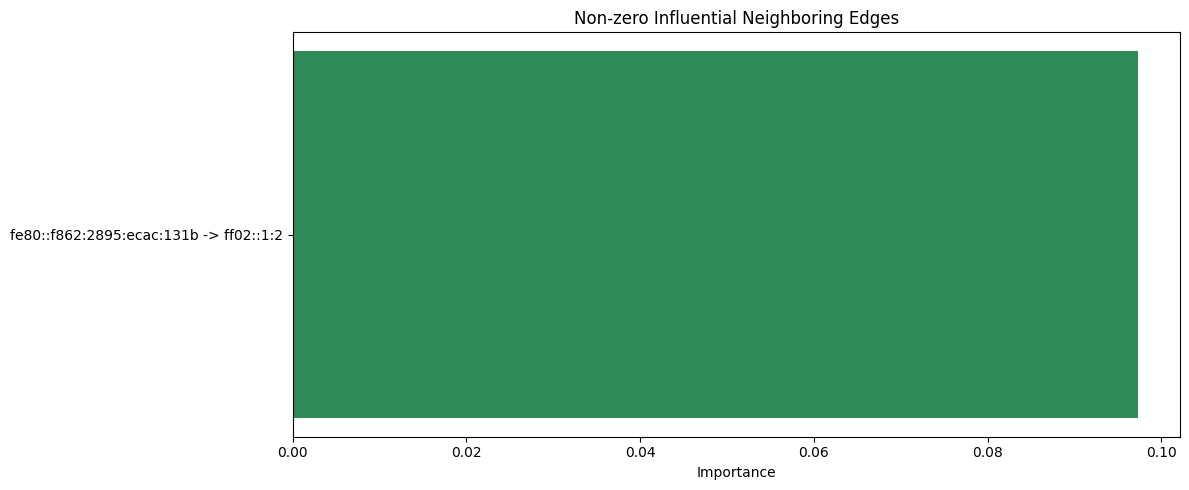

In [45]:
neighbors = binary_explanation[
    "important_neighbor_edges"
]

if neighbors:
    labels = [
        f"{item['source_ip']} -> {item['destination_ip']}"
        for item in neighbors
    ]
    values = [
        item["importance"] for item in neighbors
    ]

    plt.figure(figsize=(12, 5))
    plt.barh(labels[::-1], values[::-1], color="seagreen")
    plt.xlabel("Importance")
    plt.title("Non-zero Influential Neighboring Edges")
    plt.tight_layout()
    plt.show()
else:
    print("No non-zero neighboring edges were found.")

## 12. Consistency summary across explained edges

In [46]:
from collections import Counter

node_feature_counts = Counter()
edge_feature_counts = Counter()

for record in ui_records:
    explanation = record[
        "explanations"
    ]["binary"]

    for item in explanation[
        "important_node_features"
    ]:
        node_feature_counts[item["feature"]] += 1

    for item in explanation[
        "important_edge_features"
    ]:
        edge_feature_counts[item["feature"]] += 1

print("Most frequent binary node features:")
print(node_feature_counts.most_common(10))

print("Most frequent binary edge features:")
print(edge_feature_counts.most_common(10))

Most frequent binary node features:
[('outgoing_missed_bytes', 16), ('outgoing_tcp_count', 15), ('unique_destinations', 7), ('incoming_resp_bytes', 6), ('outgoing_icmp_count', 6), ('outgoing_orig_ip_bytes', 5), ('incoming_missed_bytes', 5), ('incoming_udp_count', 5), ('outgoing_edge_count', 5), ('outgoing_udp_count', 4)]
Most frequent binary edge features:
[('udp_count', 20), ('connection_count', 20), ('most_common_service_unknown', 18), ('most_common_destination_port', 15), ('tcp_count', 13), ('total_orig_ip_bytes', 11), ('total_orig_packets', 3)]
